In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

Resim başarıyla yüklendi!
Resim boyutu: (418, 426)
Dört filtre başarıyla uygulandı!


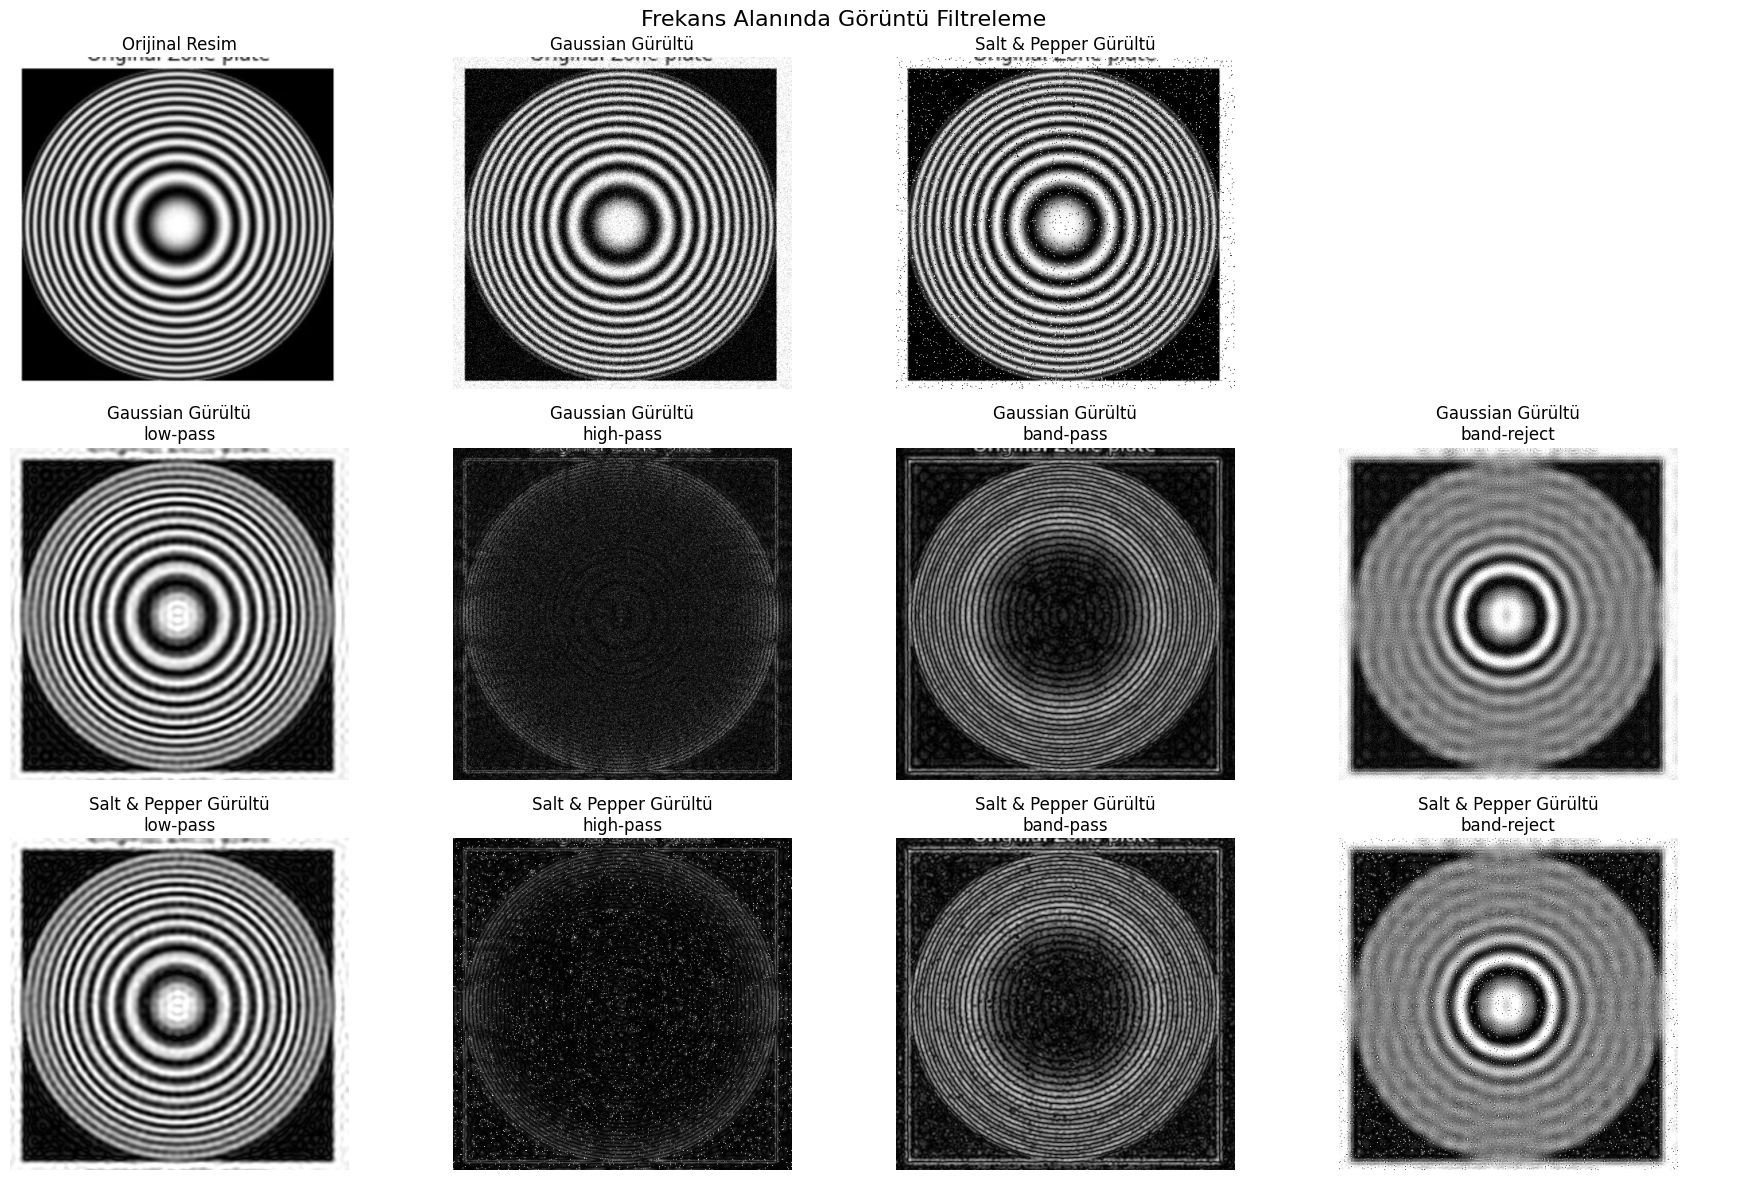

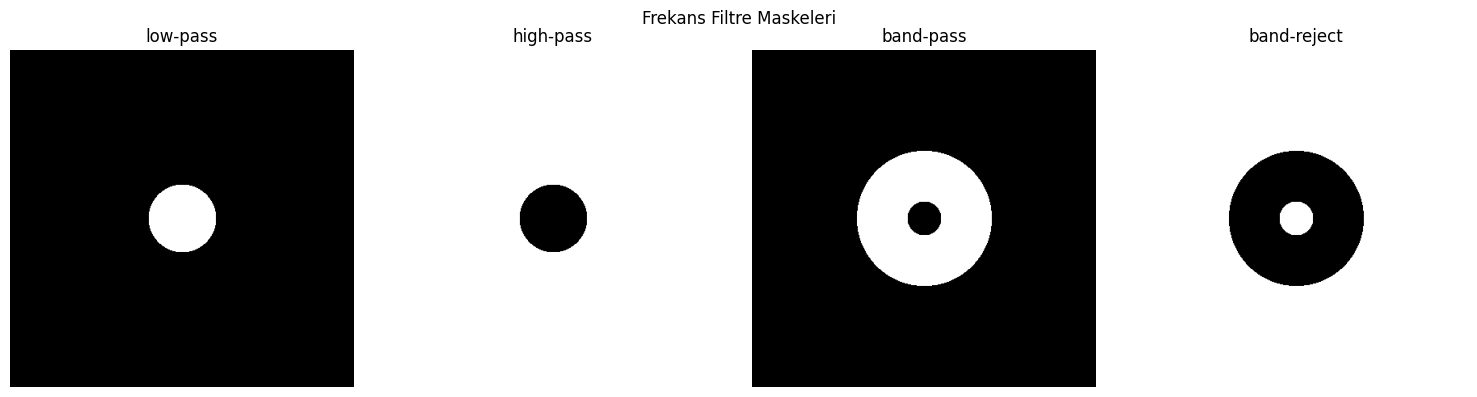


--- ORTALAMA PARLAKLIK DEĞERLERİ ---
Orijinal: 120.52
Gaussian: 120.94
Salt & Pepper: 120.99

 Gaussian Gürültü
low-pass: 121.32
high-pass: 23.98
band-pass: 46.18
band-reject: 121.98

 Salt & Pepper Gürültü
low-pass: 121.61
high-pass: 23.59
band-pass: 46.07
band-reject: 123.10

TÜM İŞLEMLER TAMAMLANDI!


In [13]:

import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

# ==========================================
# 1. RESMİ YÜKLE
# ==========================================

resim_yolu = "/content/resim7.jpg"

resim = np.array(
    Image.open(resim_yolu).convert("L")
).astype(np.float64)

print("Resim başarıyla yüklendi!")
print("Resim boyutu:", resim.shape)


# ==========================================
# 2. GAUSSIAN GÜRÜLTÜ EKLE
# ==========================================

def gaussian_gurultu(resim, sigma=25):

    gurultu = np.random.normal(
        0, sigma, resim.shape
    )

    sonuc = resim + gurultu

    return np.clip(sonuc, 0, 255)


# ==========================================
# 3. SALT & PEPPER GÜRÜLTÜ EKLE
# ==========================================

def salt_pepper_gurultu(resim, oran=0.05):

    sonuc = resim.copy()

    rastgele = np.random.random(resim.shape)

    sonuc[rastgele < oran / 2] = 0
    sonuc[rastgele > 1 - oran / 2] = 255

    return sonuc


# Gürültülü görüntüleri oluştur
gaussian_resim = gaussian_gurultu(resim)
salt_pepper_resim = salt_pepper_gurultu(resim)


# ==========================================
# 4. FREKANS ALANINDA FİLTRE FONKSİYONU
# ==========================================

def frekans_filtresi(resim, filtre_turu):

    yukseklik, genislik = resim.shape

    # Fourier dönüşümü
    dft = np.fft.fft2(resim)

    # Düşük frekansları merkeze taşı
    dft_shift = np.fft.fftshift(dft)

    merkez_y = yukseklik // 2
    merkez_x = genislik // 2

    y, x = np.ogrid[:yukseklik, :genislik]

    uzaklik = np.sqrt(
        (x - merkez_x)**2 +
        (y - merkez_y)**2
    )

    # Filtre eşikleri
    D0 = min(yukseklik, genislik) * 0.10
    D1 = min(yukseklik, genislik) * 0.05
    D2 = min(yukseklik, genislik) * 0.20

    # LOW-PASS
    if filtre_turu == "low-pass":

        maske = (uzaklik <= D0).astype(float)

    # HIGH-PASS
    elif filtre_turu == "high-pass":

        maske = (uzaklik > D0).astype(float)

    # BAND-PASS
    elif filtre_turu == "band-pass":

        maske = (
            (uzaklik >= D1) &
            (uzaklik <= D2)
        ).astype(float)

    # BAND-REJECT
    elif filtre_turu == "band-reject":

        maske = (
            (uzaklik < D1) |
            (uzaklik > D2)
        ).astype(float)

    else:
        raise ValueError("Geçersiz filtre türü!")

    # Filtreyi uygula
    filtrelenmis_dft = dft_shift * maske

    # Ters Fourier dönüşümü
    ters_dft = np.fft.ifftshift(filtrelenmis_dft)

    sonuc = np.fft.ifft2(ters_dft)

    sonuc = np.abs(sonuc)

    return np.clip(sonuc, 0, 255), maske


# ==========================================
# 5. DÖRT FİLTREYİ UYGULA
# ==========================================

filtreler = [
    "low-pass",
    "high-pass",
    "band-pass",
    "band-reject"
]

gurultulu_goruntuler = {
    "Gaussian Gürültü": gaussian_resim,
    "Salt & Pepper Gürültü": salt_pepper_resim
}

sonuclar = {}

for gurultu_adi, gurultulu_resim in gurultulu_goruntuler.items():

    sonuclar[gurultu_adi] = {}

    for filtre in filtreler:

        filtreli_resim, maske = frekans_filtresi(
            gurultulu_resim,
            filtre
        )

        sonuclar[gurultu_adi][filtre] = filtreli_resim

print("Dört filtre başarıyla uygulandı!")


# ==========================================
# 6. SONUÇLARI GÖRSELLEŞTİR
# ==========================================

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

# Orijinal resim
axes[0, 0].imshow(resim, cmap="gray")
axes[0, 0].set_title("Orijinal Resim")

# Gaussian gürültü
axes[0, 1].imshow(gaussian_resim, cmap="gray")
axes[0, 1].set_title("Gaussian Gürültü")

# Salt & Pepper gürültü
axes[0, 2].imshow(salt_pepper_resim, cmap="gray")
axes[0, 2].set_title("Salt & Pepper Gürültü")

axes[0, 3].axis("off")

# Filtre sonuçları
for satir, gurultu_adi in enumerate(gurultulu_goruntuler, start=1):

    for sutun, filtre in enumerate(filtreler):

        axes[satir, sutun].imshow(
            sonuclar[gurultu_adi][filtre],
            cmap="gray"
        )

        axes[satir, sutun].set_title(
            gurultu_adi + "\n" + filtre
        )

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    "Frekans Alanında Görüntü Filtreleme",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ==========================================
# 7. FİLTRE MASKELERİNİ GÖSTER
# ==========================================

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for ax, filtre in zip(axes, filtreler):

    _, maske = frekans_filtresi(
        gaussian_resim,
        filtre
    )

    ax.imshow(maske, cmap="gray")
    ax.set_title(filtre)
    ax.axis("off")

plt.suptitle("Frekans Filtre Maskeleri")
plt.tight_layout()
plt.show()


# ==========================================
# 8. PARLAKLIK DEĞERLERİNİ KARŞILAŞTIR
# ==========================================

print("\n--- ORTALAMA PARLAKLIK DEĞERLERİ ---")

print("Orijinal:", round(np.mean(resim), 2))
print("Gaussian:", round(np.mean(gaussian_resim), 2))
print("Salt & Pepper:", round(np.mean(salt_pepper_resim), 2))

for gurultu_adi in sonuclar:

    print("\n", gurultu_adi)

    for filtre in filtreler:

        ortalama = np.mean(
            sonuclar[gurultu_adi][filtre]
        )

        print(f"{filtre}: {ortalama:.2f}")


print("\nTÜM İŞLEMLER TAMAMLANDI!")
